# Polychromatic Beam

In [31]:
import itertools
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import profile_line
from skimage.transform import radon, iradon, rescale
from skimage.data import shepp_logan_phantom, camera, checkerboard, coins, moon, brain
from skimage import img_as_float

In [32]:
def read_xcom(path):
    """Read an XCOM text download: energy [MeV] and mu/rho [cm^2/g]."""
    E, mu_rho = np.loadtxt(path, skiprows=2, unpack=True)
    return E, mu_rho

# name -> (file, density [g/cm^3])
files = {"water": ("H2O_total_mu.txt", 1.00),
         "bone":  ("bone_total_mu.txt", 1.92),
         "iron":  ("Fe_total_mu.txt", 7.87),
         "aluminum": ("Al_total_mu.txt", 2.70),}

# Read each file once: name -> (energies, mu/rho, density)
xcom = {}
for name, (path, rho) in files.items():
    E, mu_rho = read_xcom(path)
    xcom[name] = (E, mu_rho, rho)

n_pixel = 256
pixel_size = 1.0 
L_img = n_pixel * pixel_size
ext = (0, L_img, L_img, 0)

def mu_at(name, energy):
    """Linear attenuation coefficient [1/mm] of `name` at `energy` [MeV]."""
    E, mu_rho, rho = xcom[name]
    mu_rho_E = np.exp(np.interp(np.log(energy), np.log(E), np.log(mu_rho)))
    return mu_rho_E * rho / 10 # convert from [cm^2/g] * [g/cm^3] to [1/mm]

def sample_image(materials, n_pixel, pixel_size, seed=None):
    """
    Make a sample image of circular materials.

    materials  : list of (mu, radius) pairs, radius in mm. The first is the
                 container, placed in the centre; the others go at random
                 positions inside it without overlapping.
    n_pixel    : the image is n_pixel x n_pixel
    pixel_size : mm per pixel
    seed       : a fixed number gives the same placement every run

    Returns the image and one boolean mask per material.
    """
    # Set up the random number generator
    rng = np.random.default_rng(seed)

    # Create a grid of pixel coordinates
    yy, xx = np.mgrid[:n_pixel, :n_pixel]

    # Convert radii from mm to pixels and place the circles
    radii = [r / pixel_size for _, r in materials]
    R, c = radii[0], (n_pixel - 1) / 2

    if R > n_pixel / 2:
        raise ValueError("The container does not fit in the image")

    # Place the container in the centre, then try to place the others randomly
    centres = [(c, c)]
    for r in radii[1:]:
        # Try 1000 times to place the circle without overlapping the others and inside the container
        for _ in range(1000):
            x, y = rng.uniform(c - (R - r), c + (R - r), size=2)
            inside = np.hypot(x - c, y - c) <= R - r - 1
            free = all(np.hypot(x - xj, y - yj) >= r + rj + 1
                       for (xj, yj), rj in zip(centres[1:], radii[1:]))
            if inside and free:
                centres.append((x, y))
                break
        else:
            raise RuntimeError("Could not place all circles; try smaller or fewer")

    # Create boolean masks for each material; True if the material is present, False otherwise. The first mask is the container, the others are the materials inside it.
    masks = [(xx - x) ** 2 + (yy - y) ** 2 <= r ** 2 for (x, y), r in zip(centres, radii)]
    if len(masks) > 1:
        masks[0] &= ~np.any(masks[1:], axis=0)          # holes in the container

    # Create the image by assigning the linear attenuation coefficient mu to each pixel according to the masks
    image = np.zeros((n_pixel, n_pixel))
    for (mu, _), mask in zip(materials, masks):
        image[mask] = mu

    # Centres in mm, in the same coordinates as plots with extent=(0, L_img, L_img, 0)
    centres_mm = [((x + 0.5) * pixel_size, (y + 0.5) * pixel_size) for x, y in centres]
    
    return image, masks, centres_mm

In [33]:
def mu_image_at(sample, energy, seed=42):
    """Image of mu [1/mm] at one energy [MeV]. The same seed gives the same placement at every energy."""
    materials = [(mu_at(name, energy), r) for name, r in sample]
    image, _, _ = sample_image(materials, n_pixel, pixel_size, seed=seed)
    return image


def polychromatic_sinogram(energies, weights, sample, theta, seed=42):
    """Sinogram -ln(I/I0) measured with a polychromatic beam [1/mm * px]."""
    weights = weights / np.sum(weights)
    I = 0
    for E, w in zip(energies, weights):
        p_E = radon(mu_image_at(sample, E, seed), theta=theta) * pixel_size
        I = I + w * np.exp(-p_E)                    # detector sums photons from all energies
    return -np.log(I) / pixel_size




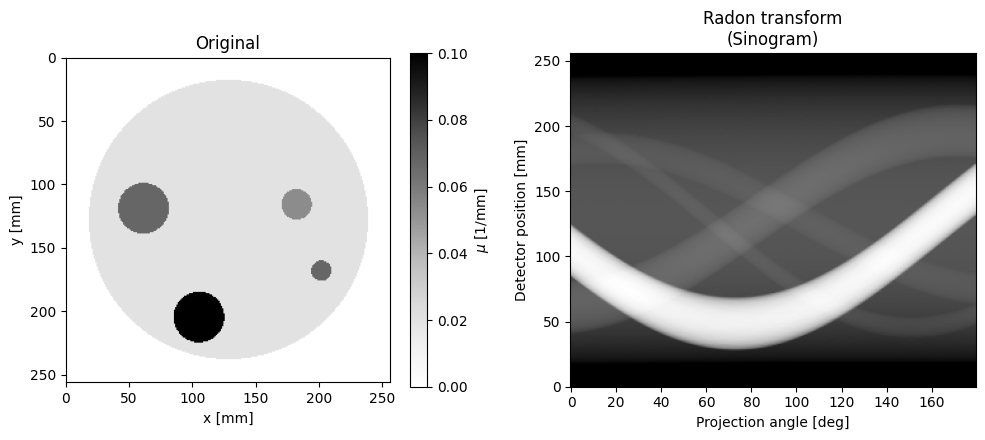

In [34]:
sample = [("water", 110.0),
          ("bone", 12.0),
          ("aluminum", 8.0),
          ("aluminum", 20.0),
          ("iron", 20.0)]

# Simple spectrum shape for a 120 kVp tube (placeholder; replace with a real spectrum later)
energies = np.linspace(0.03, 0.12, 19)                       # MeV
weights = (0.12 - energies) * energies                       # zero at 0 and at the tube voltage
E_mean = np.sum(weights * energies) / np.sum(weights)

image_ref = mu_image_at(sample, E_mean)               # reference: mu at the mean energy


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

ax1.set_title("Original")
im1 = ax1.imshow(image_ref, cmap="Greys", vmin=0, vmax=0.1, extent=ext)
ax1.set_xlabel("x [mm]")
ax1.set_ylabel("y [mm]")
fig.colorbar(im1, ax=ax1, label=r"$\mu$ [1/mm]")

# Compute the Radon transform (sinogram) of the image
theta_max = 180.0 # change this to see the effect of number of projections on the reconstruction
theta = np.linspace(0.0, theta_max, max(image_ref.shape), endpoint=False)
sinogram = polychromatic_sinogram(energies, weights, sample, theta)
dtheta = theta_max / len(theta)              # angle step [deg]
det_len = sinogram.shape[0] * pixel_size     # detector length [mm]

ax2.set_title("Radon transform\n(Sinogram)")
ax2.set_xlabel("Projection angle [deg]")
ax2.set_ylabel("Detector position [mm]")
im2 = ax2.imshow(
    sinogram * pixel_size,                   # line integral of mu, unitless
    cmap=plt.cm.Greys_r,
    extent=(-dtheta / 2, theta_max - dtheta / 2, 0, det_len),   # 0 at the bottom
    origin="lower",                          # row 0 drawn at the bottom
    aspect='auto')

fig.tight_layout()
plt.show()

FBP rms reconstruction error: 0.0604


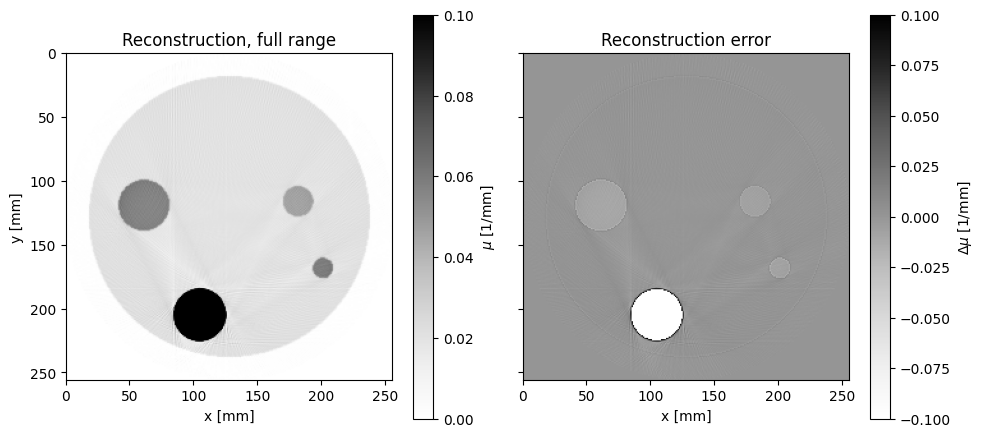

In [35]:
reconstruction_poly = iradon(sinogram, theta=theta, filter_name='ramp')
error = reconstruction_poly - image_ref

print(f'FBP rms reconstruction error: {np.sqrt(np.mean(error**2)):.3g}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)

im1 = ax1.imshow(reconstruction_poly, cmap="Greys", vmin=0, vmax=0.1, extent=ext)
ax1.set_title("Reconstruction, full range")
fig.colorbar(im1, ax=ax1, label=r"$\mu$ [1/mm]")

im2 = ax2.imshow(error, cmap="Greys", vmin=-0.1, vmax=0.1, extent=ext)
ax2.set_title("Reconstruction error")
fig.colorbar(im2, ax=ax2, label=r"$\Delta\mu$ [1/mm]")

for ax in (ax1, ax2):
    ax.set_xlabel("x [mm]")
ax1.set_ylabel("y [mm]")
fig.tight_layout()
plt.show()